# Clase 6: Integración, Benchmarking y Cierre del Bloque 1

### Machine Learning (RIA-805) — Octavo Ciclo — Robótica e Inteligencia Artificial

**Docente:** Marco Capio  
**Fecha:** Semana 3 — Bloque 1

**Objetivo:** Integrar todos los componentes del pipeline de ML en un flujo modular y reproducible, medir latencia de inferencia, documentar el proyecto y preparar la entrega final de la Práctica 1.

**Conexión con la práctica:** Esta clase es el cierre del Bloque 1. En APE 9 van a entregar la Práctica 1 completa. Hoy veremos cómo integrar todo, cómo medir latencia y cómo documentar como se hace en producción.

## ¿Qué hemos aprendido en el Bloque 1?

- **Clase 1:** Repaso general con Iris (pipeline completo).
- **Clase 2:** Carga de datos y EDA profesional.
- **Clase 3:** Preprocesamiento avanzado (imputación, escalado, Data Leakage).
- **Clase 4:** Modelos supervisados (Random Forest, XGBoost, SVM).
- **Clase 5:** Modelos no supervisados (K-Means, DBSCAN, PCA, t-SNE).

Hoy integramos todo en un pipeline modular, medimos latencia y documentamos. El propósito no es solo obtener métricas: también dejamos artefactos que otra persona pueda reproducir y revisar.

In [ ]:
# Importamos las herramientas necesarias para datos, visualización, modelos y persistencia.
import json
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Configuramos el estilo de las figuras y evitamos que warnings no críticos oculten resultados.
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
os.makedirs('reports/figures', exist_ok=True)
os.makedirs('models', exist_ok=True)

## Paso 1: Pipeline modular

Un **pipeline modular** divide el flujo de trabajo en funciones independientes y reutilizables. Cada función recibe datos claros, realiza una tarea acotada y devuelve un resultado explícito.

**Ventajas:** reproducible, testeable, mantenible y escalable. Si una etapa falla, podemos localizarla y corregirla sin reescribir todo el proceso.

En producción, normalmente no se entrena un modelo directamente en un notebook. Se usan scripts modulares que se pueden ejecutar en cualquier orden y entorno controlado. Hoy integraremos funciones como las que ya creamos en las clases anteriores.

> **Recordatorio sobre Data Leakage:** primero dividimos los datos en entrenamiento y prueba. El escalador se ajusta solamente con entrenamiento y luego transforma ambos conjuntos.

In [ ]:
# Funciones reutilizables del pipeline: carga, preparación, entrenamiento y evaluación.
def cargar_datos(path):
    '''Carga un archivo Parquet y devuelve sus datos como DataFrame.'''
    if not os.path.exists(path):
        raise FileNotFoundError(f'No se encontró el archivo de datos: {path}')
    return pd.read_parquet(path)


def preparar_datos(df, target_col):
    '''Separa características y objetivo, divide y escala sin fuga de datos.

    Retorna X_train, X_test, y_train, y_test, scaler y label_encoder.
    Las características escaladas conservan nombres de columnas e índices.
    '''
    if target_col not in df.columns:
        raise ValueError(f'La columna objetivo {target_col!r} no existe en los datos.')
    if df[target_col].isna().any():
        raise ValueError(f'La columna objetivo {target_col!r} contiene valores nulos.')

    X = df.drop(columns=[target_col]).copy()
    y = df[target_col].copy()
    if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
        raise ValueError('Todas las características deben ser numéricas antes de escalar.')

    label_encoder = LabelEncoder()
    y_encoded = label_encoder.fit_transform(y)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=0.2, random_state=RANDOM_STATE, stratify=y_encoded
    )

    scaler = RobustScaler()
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
    )
    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test), columns=X.columns, index=X_test.index
    )
    return X_train_scaled, X_test_scaled, y_train, y_test, scaler, label_encoder


def entrenar_modelo(modelo, X_train, y_train):
    '''Ajusta el modelo y retorna el modelo entrenado y su tiempo en segundos.'''
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tiempo_entrenamiento = time.perf_counter() - inicio
    return modelo, tiempo_entrenamiento


def evaluar_modelo(modelo, X_test, y_test):
    '''Calcula accuracy, F1 weighted y el tiempo de inferencia por lote.'''
    inicio = time.perf_counter()
    predicciones = modelo.predict(X_test)
    tiempo_inferencia = time.perf_counter() - inicio
    return {
        'accuracy': accuracy_score(y_test, predicciones),
        'f1_score': f1_score(y_test, predicciones, average='weighted'),
        'inference_time_s': tiempo_inferencia,
    }


# Persistimos artefactos y reportes en formatos interoperables.
def guardar_modelo(modelo, path):
    '''Guarda un modelo ajustado en la ruta indicada usando joblib.'''
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    joblib.dump(modelo, path)
    return path


def medir_latencia(modelo, X_test, n=100):
    '''Mide el promedio en milisegundos de predicciones individuales.'''
    if n <= 0:
        raise ValueError('n debe ser un entero positivo.')
    if len(X_test) == 0:
        raise ValueError('X_test no puede estar vacío.')

    cantidad = min(n, len(X_test))
    duraciones = []
    for indice in range(cantidad):
        muestra = X_test.iloc[[indice]] if hasattr(X_test, 'iloc') else X_test[indice:indice + 1]
        inicio = time.perf_counter()
        modelo.predict(muestra)
        duraciones.append(time.perf_counter() - inicio)
    return float(np.mean(duraciones) * 1000)


def guardar_reporte(reporte, path):
    '''Guarda un diccionario como JSON, creando antes la carpeta destino.'''
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    with open(path, 'w', encoding='utf-8') as archivo:
        json.dump(reporte, archivo, ensure_ascii=False, indent=2)
    return path

## Paso 2: Ejecutar el pipeline completo

Vamos a cargar los datos, prepararlos, entrenar tres modelos supervisados y dos no supervisados, evaluar lo que corresponde a cada enfoque y guardar artefactos y métricas.

En clasificación supervisada usamos las etiquetas conocidas para medir accuracy y F1. En clustering no tenemos etiquetas para evaluar de esa manera; usamos silhouette cuando la partición permite calcularlo y explicamos las limitaciones. Este es el flujo que deben adaptar a su Práctica 1.

In [ ]:
# Buscamos el Parquet desde la carpeta actual y sus carpetas padre.
ruta_relativa = 'data/processed/crop.parquet'
directorio = os.getcwd()
DATA_PATH = None

while True:
    candidato = os.path.join(directorio, ruta_relativa)
    if os.path.isfile(candidato):
        DATA_PATH = candidato
        break
    padre = os.path.dirname(directorio)
    if padre == directorio:
        break
    directorio = padre

if DATA_PATH is None:
    raise FileNotFoundError(
        f'No se encontró {ruta_relativa}. Comprueba que el archivo exista '
        'en la carpeta data/processed del proyecto.'
    )

# Usamos la columna label como variable objetivo.
TARGET_COL = 'label'
df = cargar_datos(DATA_PATH)
X_train_scaled, X_test_scaled, y_train, y_test, scaler, label_encoder = preparar_datos(df, TARGET_COL)

# Definimos modelos con una semilla fija para facilitar la reproducibilidad.
modelos_supervisados = {
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1, random_state=RANDOM_STATE,
        n_jobs=1, objective='multi:softprob', eval_metric='mlogloss'
    ),
    'SVM': SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE),
}

resultados = []
modelos_entrenados = {}
for nombre, modelo in modelos_supervisados.items():
    modelo, tiempo_entrenamiento = entrenar_modelo(modelo, X_train_scaled, y_train)
    metricas = evaluar_modelo(modelo, X_test_scaled, y_test)
    latencia_ms = medir_latencia(modelo, X_test_scaled, n=100)
    ruta_modelo = f'models/{nombre.lower().replace(" ", "_")}.joblib'
    guardar_modelo(modelo, ruta_modelo)
    modelos_entrenados[nombre] = modelo
    resultados.append({
        'model': nombre,
        'type': 'Supervisado',
        'accuracy': float(metricas['accuracy']),
        'f1_score': float(metricas['f1_score']),
        'latency_ms': latencia_ms,
        'training_time_s': tiempo_entrenamiento,
        'silhouette': None,
        'latency_measurement': 'predicción individual',
        'model_path': ruta_modelo,
    })
    print(
        f'{nombre}: accuracy={metricas["accuracy"]:.4f}, '
        f'F1={metricas["f1_score"]:.4f}, latencia={latencia_ms:.4f} ms, '
        f'entrenamiento={tiempo_entrenamiento:.3f} s'
    )

Random Forest: accuracy=0.9955, F1=0.9955, latencia=40.2980 ms, entrenamiento=0.364 s
XGBoost: accuracy=0.9864, F1=0.9862, latencia=2.6380 ms, entrenamiento=0.821 s
SVM: accuracy=0.9841, F1=0.9840, latencia=0.9485 ms, entrenamiento=0.038 s


In [ ]:
# Ajustamos clustering sobre las características de entrenamiento sin usar y_train.
modelos_no_supervisados = {
    'K-Means': KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10),
    'DBSCAN': DBSCAN(eps=0.5, min_samples=5),
}

def silhouette_seguro(X, etiquetas, excluir_ruido=False):
    '''Calcula silhouette solo si hay al menos dos clusters válidos.'''
    etiquetas = np.asarray(etiquetas)
    mascara = etiquetas != -1 if excluir_ruido else np.ones(len(etiquetas), dtype=bool)
    etiquetas_validas = etiquetas[mascara]
    if len(etiquetas_validas) < 2 or len(np.unique(etiquetas_validas)) < 2:
        return None
    return float(silhouette_score(np.asarray(X)[mascara], etiquetas_validas))

for nombre, modelo in modelos_no_supervisados.items():
    modelo, tiempo_entrenamiento = entrenar_modelo(modelo, X_train_scaled, None)
    excluir_ruido = nombre == 'DBSCAN'
    silhouette = silhouette_seguro(
        X_train_scaled, modelo.labels_, excluir_ruido=excluir_ruido
    )
    ruta_modelo = f'models/{nombre.lower().replace("-", "_")}.joblib'
    guardar_modelo(modelo, ruta_modelo)

    # K-Means admite asignar nuevos puntos; DBSCAN no expone predict, por lo que no reportamos latencia de inferencia.
    latencia_ms = medir_latencia(modelo, X_test_scaled, n=100) if nombre == 'K-Means' else None
    resultados.append({
        'model': nombre,
        'type': 'No supervisado',
        'accuracy': None,
        'f1_score': None,
        'latency_ms': latencia_ms,
        'training_time_s': tiempo_entrenamiento,
        'silhouette': silhouette,
        'latency_measurement': 'predicción individual' if latencia_ms is not None else 'no aplica: DBSCAN no tiene predict',
        'model_path': ruta_modelo,
    })
    silhouette_texto = f'{silhouette:.4f}' if silhouette is not None else 'no disponible (clusters insuficientes)'
    latencia_texto = f'{latencia_ms:.4f} ms' if latencia_ms is not None else 'no aplica'
    print(
        f'{nombre}: silhouette={silhouette_texto}, latencia={latencia_texto}, '
        f'entrenamiento={tiempo_entrenamiento:.3f} s'
    )

K-Means: silhouette=0.2530, latencia=0.7275 ms, entrenamiento=0.176 s
DBSCAN: silhouette=0.3666, latencia=no aplica, entrenamiento=0.026 s


## Paso 3: Benchmarking de latencia

La **latencia** es el tiempo que tarda un modelo en producir una predicción. En producción importa tanto como la calidad: si un robot necesita reaccionar en tiempo real, un modelo demasiado lento puede no ser adecuado aunque tenga buena precisión.

Aquí medimos predicciones de una fila para los modelos que ofrecen `predict`, promediando hasta 100 muestras de prueba. Es una comparación orientativa: el hardware, el tamaño de entrada y la carga del sistema cambian los tiempos. DBSCAN no admite inferencia de puntos nuevos con `predict`; por eso se informa su tiempo de entrenamiento y la latencia queda como no disponible.

       modelo           tipo  latencia_promedio_ms  tiempo_entrenamiento_s
Random Forest    Supervisado             40.297953                0.364065
      XGBoost    Supervisado              2.637952                0.821028
          SVM    Supervisado              0.948490                0.037801
      K-Means No supervisado              0.727523                0.175512
       DBSCAN No supervisado             No aplica                0.026424


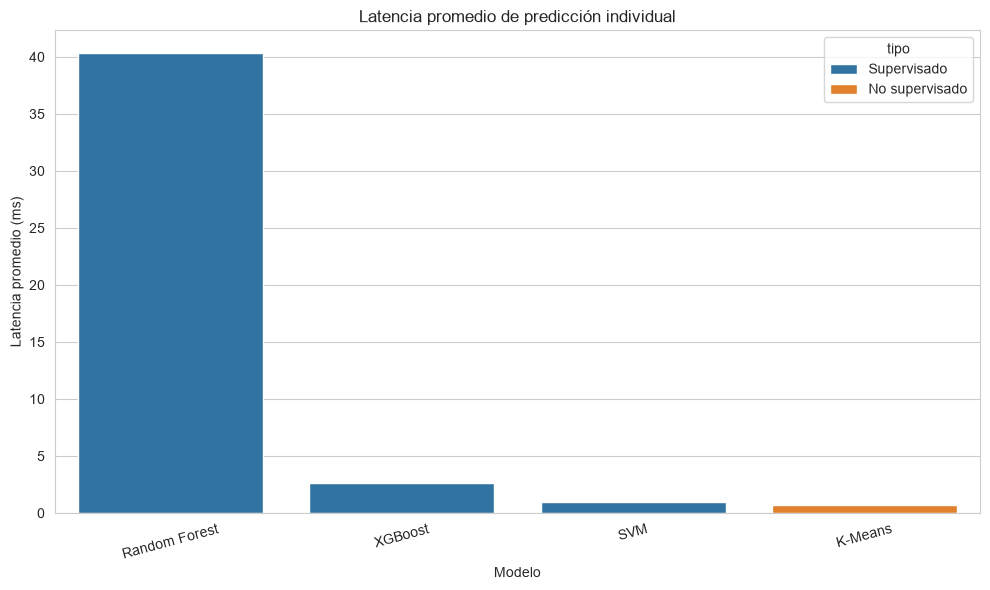

'reports/resultados_pipeline.json'

In [ ]:
# Construimos una tabla comparable; DBSCAN conserva latencia vacía porque no ofrece predict.
benchmark = pd.DataFrame([
    {
        'modelo': resultado['model'],
        'tipo': resultado['type'],
        'latencia_promedio_ms': resultado['latency_ms'],
        'tiempo_entrenamiento_s': resultado['training_time_s'],
    }
    for resultado in resultados
])
print(benchmark.to_string(index=False, na_rep='No aplica'))

os.makedirs('reports/figures', exist_ok=True)
benchmark.to_csv('reports/benchmark_latencia.csv', index=False)

# Graficamos solo los modelos con una latencia de predicción medible.
datos_grafico = benchmark.dropna(subset=['latencia_promedio_ms'])
fig, ax = plt.subplots()
sns.barplot(data=datos_grafico, x='modelo', y='latencia_promedio_ms', hue='tipo', ax=ax)
ax.set_title('Latencia promedio de predicción individual')
ax.set_xlabel('Modelo')
ax.set_ylabel('Latencia promedio (ms)')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig('reports/figures/benchmark_latencia.png', dpi=150, bbox_inches='tight')
plt.show()

guardar_reporte(resultados, 'reports/resultados_pipeline.json')

## Paso 4: Documentación

Un proyecto de ML que se acerca a producción debe poder entenderse, instalarse y ejecutarse por otras personas. La documentación forma parte del entregable y reduce errores al transferir o mantener el proyecto.

Elementos clave:

- **README.md:** descripción, estructura, instalación, ejecución y resultados.
- **Docstrings** en funciones para explicar propósito, parámetros y retornos.
- **Comentarios** en código para aclarar decisiones no obvias.
- **requirements.txt** para declarar dependencias y facilitar la reproducción.

En la Práctica 1, su README debe tener todo esto y reflejar los resultados realmente obtenidos.

In [ ]:
def generar_readme(resultados, path='README.md'):
    '''Genera un README con instrucciones y resultados del pipeline ejecutado.'''
    filas = []
    for resultado in resultados:
        accuracy = f"{resultado['accuracy']:.4f}" if resultado['accuracy'] is not None else 'No aplica'
        f1 = f"{resultado['f1_score']:.4f}" if resultado['f1_score'] is not None else 'No aplica'
        silhouette = f"{resultado['silhouette']:.4f}" if resultado['silhouette'] is not None else 'No disponible'
        latencia = f"{resultado['latency_ms']:.4f} ms" if resultado['latency_ms'] is not None else 'No aplica'
        filas.append(
            f"| {resultado['model']} | {resultado['type']} | {accuracy} | {f1} | "
            f"{silhouette} | {latencia} | {resultado['training_time_s']:.3f} s |"
        )

    contenido = '''# Práctica 1 — Pipeline de Machine Learning

## Descripción
Proyecto educativo que integra carga y preparación de datos, modelos supervisados y no supervisados, evaluación, benchmarking y persistencia de artefactos.

## Estructura del repositorio
```text
proyecto/
├── data/processed/crop.parquet
├── models/
├── notebooks/
├── reports/figures/
├── requirements.txt
└── README.md
```

## Instalación
Cree un entorno virtual y luego instale las dependencias declaradas:
```bash
python -m venv .venv
python -m pip install -r requirements.txt
```

## Ejecución
Desde la raíz del repositorio, abra y ejecute todas las celdas de `notebooks/clase_6_integracion.ipynb` en orden. Los modelos se guardan en `models/` y los reportes en `reports/`.

## Resultados
| Modelo | Tipo | Accuracy | F1 weighted | Silhouette | Latencia individual | Entrenamiento |
|---|---|---:|---:|---:|---:|---:|
'''
    contenido += '\n'.join(filas)
    contenido += '\n\nLa latencia corresponde a predicción individual. DBSCAN no implementa `predict`; por tanto, su latencia de inferencia se reporta como no aplicable. Silhouette no se calcula cuando no hay al menos dos clusters válidos.\n'

    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    with open(path, 'w', encoding='utf-8') as archivo:
        archivo.write(contenido)
    return contenido


readme_generado = generar_readme(resultados)
print(readme_generado)

## Paso 5: Estructura del repositorio

Separar datos, código fuente, modelos, notebooks y reportes hace que el proyecto sea más fácil de navegar y mantener. Los notebooks son útiles para explorar y comunicar; la lógica estable suele migrarse a módulos dentro de `src/`.

Esta es una estructura ideal de referencia para un repositorio de ML en producción y la estructura que deben procurar tener en su Práctica 1:

```text
proyecto/
├── data/
│   ├── raw/
│   └── processed/
├── src/
│   ├── data_loader.py
│   ├── train_supervised.py
│   ├── train_unsupervised.py
│   └── pipeline.py
├── models/
├── notebooks/
├── reports/
│   ├── figures/
│   └── benchmark_latencia.csv
├── requirements.txt
└── README.md
```

Los datos de entrada deben estar disponibles en la ruta documentada y los artefactos generados no deben confundirse con el código fuente.

## Paso 6: Clean Code

Buenas prácticas que hacen más confiable y legible el trabajo del equipo:

- **Nombres descriptivos** para variables, funciones y archivos.
- **Funciones pequeñas** con una sola responsabilidad.
- **Docstrings** que expliquen cómo usar las funciones.
- Evitar **valores hardcodeados** dispersos; centralizar parámetros que deban cambiarse.
- Evitar **Data Leakage** separando train/test antes de ajustar transformaciones.
- Usar **commits descriptivos** que expliquen el cambio realizado.

> Un código limpio vale más que un modelo complejo mal documentado. La claridad facilita revisar, reproducir y mejorar resultados.

In [ ]:
# Ejemplo sucio: mezcla transformación, entrenamiento y evaluación en un solo bloque.
def ejemplo_sucio(df):
    datos = df.dropna()
    X = datos.drop(columns=['label'])
    y = datos['label'].astype('category').cat.codes
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    scaler = RobustScaler()
    Xtr = scaler.fit_transform(Xtr)
    Xte = scaler.transform(Xte)
    modelo = RandomForestClassifier(n_estimators=100, random_state=42)
    modelo.fit(Xtr, ytr)
    return accuracy_score(yte, modelo.predict(Xte))

# Versión refactorizada: cada función tiene una tarea y puede probarse por separado.
def crear_modelo_base():
    '''Crea un clasificador base con parámetros reproducibles.'''
    return RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)


def ejecutar_ejemplo_refactorizado(df):
    '''Orquesta las funciones reutilizables para preparar, entrenar y evaluar.'''
    X_train, X_test, y_train, y_test, _, _ = preparar_datos(df, 'label')
    modelo, tiempo = entrenar_modelo(crear_modelo_base(), X_train, y_train)
    metricas = evaluar_modelo(modelo, X_test, y_test)
    return {'accuracy': metricas['accuracy'], 'training_time_s': tiempo}

print('Ejemplo de refactorización definido. Puede compararse ejecutándolo con el DataFrame df.')

## Conclusiones del Bloque 1

1. Un pipeline modular es reproducible y escalable.
2. La latencia importa en producción y debe medirse con contexto.
3. La documentación también es parte del entregable.
4. Data Leakage se evita separando train/test antes de ajustar el escalador.
5. El mejor modelo no es necesariamente el más preciso: es el que mejor se ajusta al problema, sus restricciones y sus usuarios.

### Conexión con Práctica 1

En APE 9 entregan la Práctica 1 completa. Debe incluir un repositorio modular, EDA, preprocesamiento, modelos supervisados, modelos no supervisados, benchmarking y README.

### Próximo bloque

**Bloque 2: Factibilidad Técnico-Financiera y Evaluación de Modelos.**

In [ ]:
# Confirmamos el cierre del Bloque 1 y recordamos dónde revisar los artefactos.
print('Clase 6 completada. Bloque 1 finalizado.')